# iAmTime forecasting on Walmart sales

This notebook repeats the workflows of [`iamtime_forecasting_usage.ipynb`](iamtime_forecasting_usage.ipynb) on real data instead of synthetic series:

1. Univariate forecasting
2. Multivariate forecasting
3. Forecasting with exogenous variables (native Walmart covariates), plus synthetic promotion-strength scenarios on top of a real series
4. Forecasting with in-context examples chosen by clustering similar series

The data is the public Walmart weekly sales dataset (`autogluon/fev_datasets`, configuration `walmart`): one weekly series of department sales per `(Store, Dept)` pair, with 10 exogenous channels. All examples load the public [`anishsaha/iAmTime-base-forecast`](https://huggingface.co/anishsaha/iAmTime-base-forecast) checkpoint.

## Setup

Install the package with the notebook and training extras from the repository root. The `training` extra provides `datasets` and `pandas`, which this notebook uses to load the Walmart data:

```bash
pip install -e ".[notebook,training]"
```

The first run downloads the checkpoint and the dataset from the Hugging Face Hub and caches them locally.

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans

from iAmTime.pipeline import iAmTimePipeline

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

In [2]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    TORCH_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
else:
    DEVICE = "cpu"
    TORCH_DTYPE = torch.float32

MODEL_ID = "anishsaha/iAmTime-base-forecast"

print(f"Device: {DEVICE}")
print(f"Dtype: {TORCH_DTYPE}")
print(f"Model: {MODEL_ID}")

Device: cpu
Dtype: torch.float32
Model: anishsaha/iAmTime-base-forecast


In [3]:
pipeline = iAmTimePipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=TORCH_DTYPE,
)
pipeline.model.eval()
print("Pipeline loaded successfully.")

Pipeline loaded successfully.


## Walmart data

Each item is a `(Store, Dept)` weekly sales series from 2010-02-05 to 2012-10-26 (143 weeks), with 10 exogenous channels that share the item's timestamps:

- `IsHoliday`: the week contains the Super Bowl, Labor Day, Thanksgiving, or Christmas.
- `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`: regional weather and economic indicators for the store.
- `MarkDown1` to `MarkDown5`: anonymised promotional markdowns. They are only recorded from November 2011, so earlier values are `NaN`. The pipeline treats `NaN` as missing.

As in the Walmart evaluation notebook, the last `HORIZON = 39` weeks (about nine months) of every series are held out as ground truth. The model sees only the first 104 weeks.

In [4]:
DATASET_PATH = "autogluon/fev_datasets"
DATASET_CONFIG = "walmart"
SERIES_LENGTH = 143
HORIZON = 39  # Weeks held out as ground truth.
HISTORY = SERIES_LENGTH - HORIZON
COVARIATES = [
    "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5",
]

walmart = load_dataset(DATASET_PATH, DATASET_CONFIG)["train"].to_pandas().set_index("id")
walmart = walmart[walmart["target"].apply(len) == SERIES_LENGTH]  # Keep complete series only.
dates = pd.DatetimeIndex(walmart["timestamp"].iloc[0])
assert all((pd.DatetimeIndex(ts) == dates).all() for ts in walmart["timestamp"])
history_dates, future_dates = dates[:HISTORY], dates[HISTORY:]

def series(item_id, column="target"):
    return np.asarray(walmart.loc[item_id, column], dtype=np.float32)

print(f"{len(walmart)} complete series, {walmart['Store'].nunique()} stores, {walmart['Dept'].nunique()} departments")
print(f"History: {history_dates[0].date()} to {history_dates[-1].date()} ({HISTORY} weeks)")
print(f"Horizon: {future_dates[0].date()} to {future_dates[-1].date()} ({HORIZON} weeks)")

2842 complete series, 45 stores, 74 departments
History: 2010-02-05 to 2012-01-27 (104 weeks)
Horizon: 2012-02-03 to 2012-10-26 (39 weeks)


### Forecast output and evaluation

`predict_quantiles` returns quantiles with shape `(batch, horizon, quantiles)` for univariate input and `(batch, variates, horizon, quantiles)` for uniform multivariate input. This notebook requests the 10th, 50th, and 90th percentiles.

Forecasts are scored with MASE: the mean absolute error of the median forecast, divided by the in-sample mean absolute error of a one-step naive forecast on the history (the same convention as the Walmart evaluation notebook). Lower is better.

In [5]:
QUANTILE_LEVELS = [0.1, 0.5, 0.9]
COLORS = {"history": "#3f4652", "truth": "#23836b", "forecast": "#8f5fa2", "reference": "#d08c2e"}
HOLIDAY_COLOR = "#377ca8"
HALF_WEEK = timedelta(days=3.5)  # Weekly points sit mid-bar; boundaries are half a week away.

def predict(input_batch, horizon=HORIZON):
    quantiles, _ = pipeline.predict_quantiles(
        input_batch,
        prediction_length=horizon,
        quantile_levels=QUANTILE_LEVELS,
    )
    return quantiles.detach().cpu().numpy() if isinstance(quantiles, torch.Tensor) else quantiles

def mase(history, truth, forecast):
    return float(np.mean(np.abs(truth - forecast)) / np.mean(np.abs(np.diff(history))))

def describe(item_id):
    store, dept = item_id.split("_")
    return f"Store {store}, dept {dept}"

sales_formatter = FuncFormatter(lambda value, _: f"{value / 1000:,.0f}k")

def plot_forecast(ax, history, truth, quantiles, title, reference=None, reference_label=None):
    ax.plot(history_dates[-len(history):], history, color=COLORS["history"], lw=1.3, label="History")
    ax.plot(future_dates, truth, color=COLORS["truth"], lw=1.5, label="Observed future")
    ax.fill_between(future_dates, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.20, label="10-90% interval")
    ax.plot(future_dates, quantiles[:, 1], color=COLORS["forecast"], lw=1.8, label="Median forecast")
    if reference is not None:
        ax.plot(future_dates, reference, color=COLORS["reference"], lw=1.3, ls="--", label=reference_label)
    ax.axvline(future_dates[0] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
    ax.yaxis.set_major_formatter(sales_formatter)
    ax.set_title(title)
    ax.set_ylabel("Weekly sales")

## 1. Univariate forecasting

The simplest input is a two-dimensional array with shape `(batch, history)`. Here the batch holds three departments of store 1 with different behaviour: department 1 has sharp holiday and spring peaks, department 92 has a strong within-month cycle, and department 95 has a slow seasonal swing.

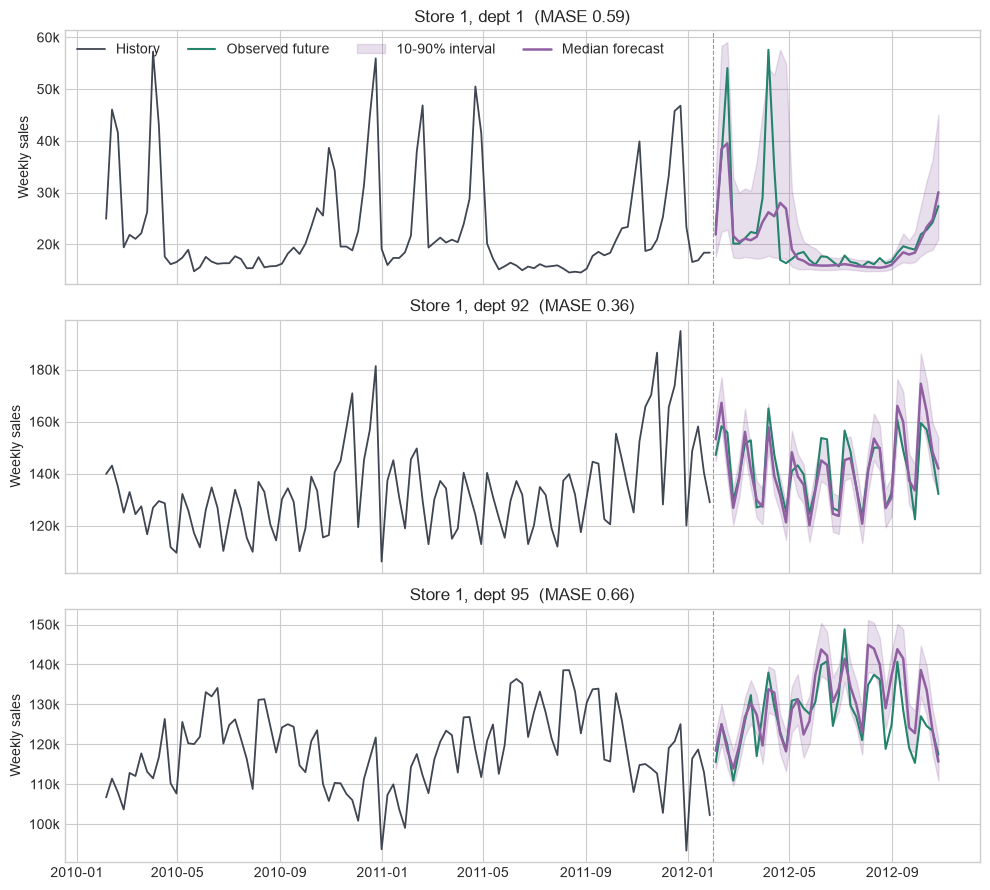

In [6]:
UNIVARIATE_IDS = ["1_1", "1_92", "1_95"]

uni_series = np.stack([series(item_id) for item_id in UNIVARIATE_IDS])
uni_input = uni_series[:, :HISTORY]  # (batch=3, history)
uni_quantiles = predict(uni_input)

fig, axes = plt.subplots(len(UNIVARIATE_IDS), 1, figsize=(10, 3.0 * len(UNIVARIATE_IDS)), sharex=True)
for ax, item_id, values, quantiles in zip(axes, UNIVARIATE_IDS, uni_series, uni_quantiles):
    score = mase(values[:HISTORY], values[HISTORY:], quantiles[:, 1])
    plot_forecast(ax, values[:HISTORY], values[HISTORY:], quantiles, f"{describe(item_id)}  (MASE {score:.2f})")
axes[0].legend(ncol=4, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## 2. Multivariate forecasting

A multivariate target has shape `(batch, variates, history)`. iAmTime forecasts every variate and uses the histories of the other variates as additional context.

Departments 23, 7, and 82 of store 8 have highly correlated histories, so their joint history is a natural multivariate input. The dashed line is the univariate forecast of the same department for comparison, and each title shows both MASE values.

This triple was **selected for the demo** because joint context improves all three departments. That is not typical: among the 4 most correlated triples of high-volume departments in each of stores 1 to 20 (80 triples), all three variates improved in only 16. In the others, joint context helps some variates and hurts others.

Correlation of the histories:
[[1.    0.891 0.847]
 [0.891 1.    0.895]
 [0.847 0.895 1.   ]]


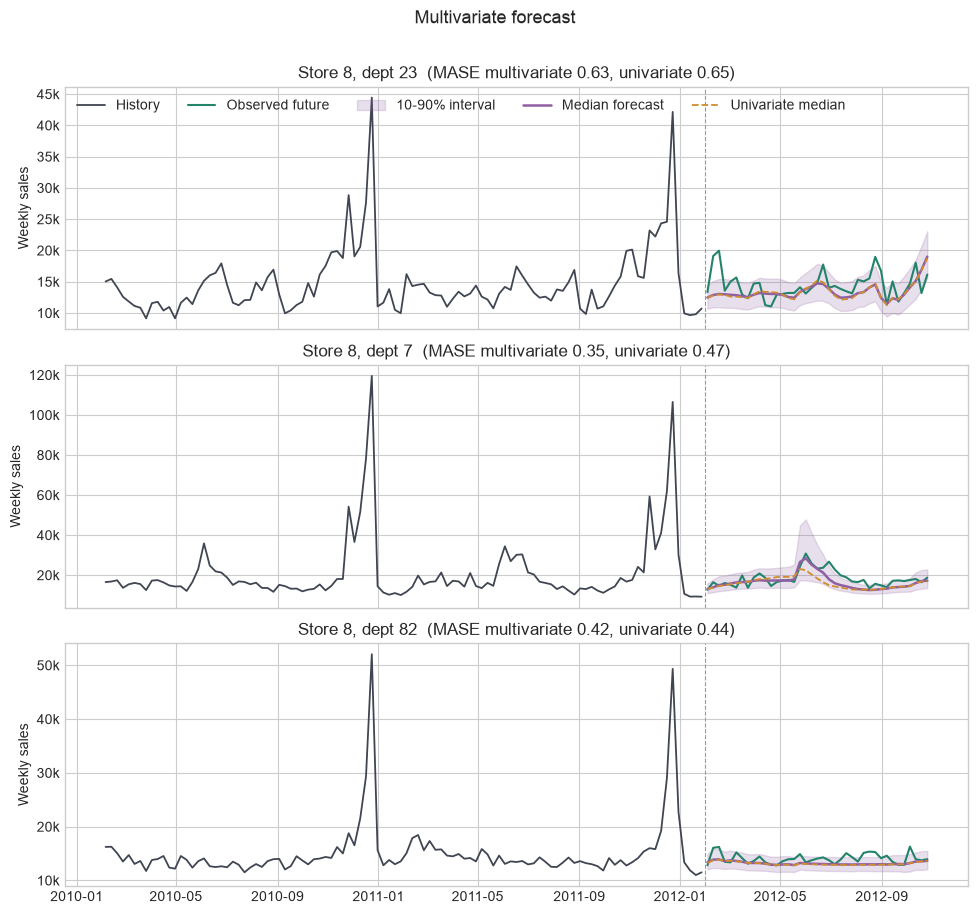

In [7]:
MULTIVARIATE_IDS = ["8_23", "8_7", "8_82"]

multi_series = np.stack([series(item_id) for item_id in MULTIVARIATE_IDS])
print("Correlation of the histories:")
print(np.corrcoef(multi_series[:, :HISTORY]))

multi_input = multi_series[None, :, :HISTORY]  # (batch=1, variates=3, history)
multi_quantiles = predict(multi_input)[0]
single_quantiles = predict(multi_series[:, :HISTORY])  # Each department on its own.

fig, axes = plt.subplots(len(MULTIVARIATE_IDS), 1, figsize=(10, 3.0 * len(MULTIVARIATE_IDS)), sharex=True)
for ax, item_id, values, quantiles, single in zip(axes, MULTIVARIATE_IDS, multi_series, multi_quantiles, single_quantiles):
    multi_score = mase(values[:HISTORY], values[HISTORY:], quantiles[:, 1])
    single_score = mase(values[:HISTORY], values[HISTORY:], single[:, 1])
    plot_forecast(ax, values[:HISTORY], values[HISTORY:], quantiles,
                  f"{describe(item_id)}  (MASE multivariate {multi_score:.2f}, univariate {single_score:.2f})",
                  reference=single[:, 1], reference_label="Univariate median")
axes[0].legend(ncol=5, frameon=False, loc="upper left")
fig.suptitle("Multivariate forecast", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 3. Forecasting with exogenous variables

Use the target-and-covariates dictionary when external drivers are available. Past covariates align with the target history; future covariates cover the forecast horizon.

This example passes all 10 native Walmart covariates for department 72 of store 1, a department with very large holiday peaks. The top panel compares the forecast with covariates against the forecast without them (dashed). The panels below show the covariates over the full history and horizon, and holiday weeks are shaded in every panel.

Note that the dataset provides the *observed* future covariates. Holidays are known in advance, but temperature, fuel price, CPI, unemployment, and markdowns would have to be forecasts or plans in a real deployment, so this setup is optimistic.

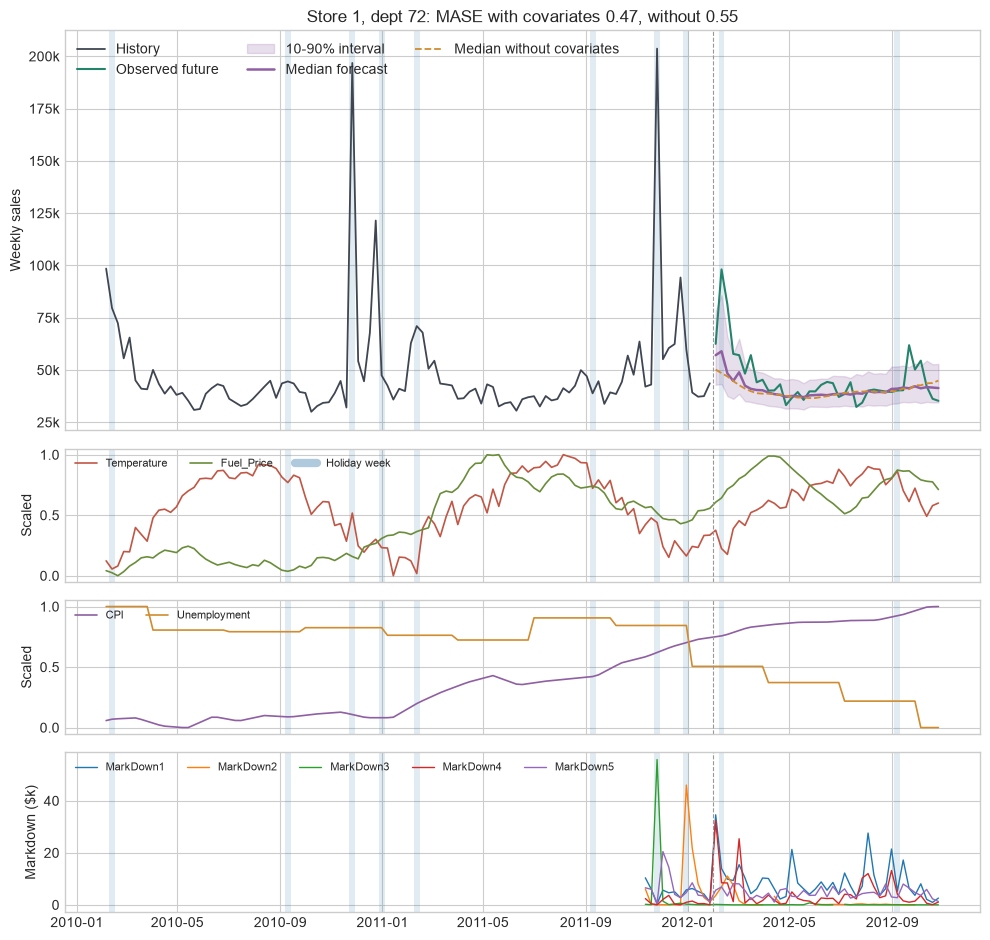

In [8]:
EXOG_ID = "1_72"

def make_covariate_input(item_id):
    covariates = {name: series(item_id, name) for name in COVARIATES}
    return {
        "target": series(item_id)[:HISTORY],
        "past_covariates": {name: values[:HISTORY] for name, values in covariates.items()},
        "future_covariates": {name: values[HISTORY:] for name, values in covariates.items()},
    }

exog_values = series(EXOG_ID)
exog_quantiles = predict([make_covariate_input(EXOG_ID)])[0]
no_exog_quantiles = predict(exog_values[None, :HISTORY])[0]
with_score = mase(exog_values[:HISTORY], exog_values[HISTORY:], exog_quantiles[:, 1])
without_score = mase(exog_values[:HISTORY], exog_values[HISTORY:], no_exog_quantiles[:, 1])

def scaled(values):
    return (values - np.nanmin(values)) / (np.nanmax(values) - np.nanmin(values))

def shade_holidays(ax):
    for week in np.flatnonzero(series(EXOG_ID, "IsHoliday")):
        ax.axvspan(dates[week] - HALF_WEEK, dates[week] + HALF_WEEK, color=HOLIDAY_COLOR, alpha=0.15, lw=0)

fig, axes = plt.subplots(4, 1, figsize=(10, 9.5), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1, 1.2]})
plot_forecast(axes[0], exog_values[:HISTORY], exog_values[HISTORY:], exog_quantiles,
              f"{describe(EXOG_ID)}: MASE with covariates {with_score:.2f}, without {without_score:.2f}",
              reference=no_exog_quantiles[:, 1], reference_label="Median without covariates")
axes[0].legend(ncol=3, frameon=False, loc="upper left")

for name, color in [("Temperature", "#c25645"), ("Fuel_Price", "#6a8d3a")]:
    axes[1].plot(dates, scaled(series(EXOG_ID, name)), color=color, lw=1.2, label=name)
for name, color in [("CPI", "#8f5fa2"), ("Unemployment", "#d08c2e")]:
    axes[2].plot(dates, scaled(series(EXOG_ID, name)), color=color, lw=1.2, label=name)
for index in range(1, 6):
    axes[3].plot(dates, series(EXOG_ID, f"MarkDown{index}") / 1000, lw=1.0, label=f"MarkDown{index}")
axes[1].set_ylabel("Scaled")
axes[2].set_ylabel("Scaled")
axes[3].set_ylabel("Markdown ($k)")
for ax in axes[1:]:
    ax.axvline(future_dates[0] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
    ax.legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
for ax in axes:
    shade_holidays(ax)
axes[1].plot([], [], color=HOLIDAY_COLOR, alpha=0.4, lw=6, label="Holiday week")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

One series is anecdotal. The cell below repeats the comparison on 64 randomly chosen series (fixed seed) and reports the mean and median MASE with and without the covariates, plus how often the covariates help.

In [9]:
rng = np.random.default_rng(0)
complete_ids = walmart.index[walmart["target"].apply(lambda values: not np.isnan(values).any())]
sample_ids = rng.choice(complete_ids, size=64, replace=False)

sample_targets = np.stack([series(item_id) for item_id in sample_ids])
without_quantiles = predict(sample_targets[:, :HISTORY])
with_quantiles = predict([make_covariate_input(item_id) for item_id in sample_ids])

scores = pd.DataFrame({
    "without covariates": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(sample_targets, without_quantiles)],
    "with covariates": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(sample_targets, with_quantiles)],
}, index=sample_ids)
print(scores.agg(["mean", "median"]).round(3).to_string())
print(f"Covariates lower MASE on {(scores['with covariates'] < scores['without covariates']).sum()} of {len(scores)} series.")

        without covariates  with covariates
mean                 0.799            0.749
median               0.722            0.725
Covariates lower MASE on 36 of 64 series.


### Promotion strength scenarios

Because future covariates are inputs, you can ask "what if" questions by changing them. Walmart's markdowns are anonymised and only cover the last year, so this example adds **synthetic** promotions on top of a real series (department 2 of store 1, a steady high-volume department):

- Two unit-strength promotions (`promotion = 1`, three weeks each) are added to the history. Each one raises sales by `PROMOTION_UPLIFT`, which is 25% of the series' average weekly sales.
- Two promotions are planned in the forecast window. Their strength is set to 1x, 2x, and 3x the historical strength, and their observed future uses the same linear effect.
- A fourth, 0x scenario (no future promotions) is the baseline. The predicted uplift is the difference between a scenario's median forecast and the 0x forecast, so forecast errors unrelated to the promotion cancel out.

All four scenarios run as one batch with `promotion` as the only covariate. At 1x the predicted uplift is close to the true one. At 2x and 3x, strengths never seen in the history, the model scales the uplift up but falls increasingly short, more so than on the clean synthetic series of the other notebook.

1x promotion from 2012-03-16: true uplift  11.4k, predicted uplift  11.1k
1x promotion from 2012-07-06: true uplift  11.4k, predicted uplift  12.2k
2x promotion from 2012-03-16: true uplift  22.9k, predicted uplift  18.2k
2x promotion from 2012-07-06: true uplift  22.9k, predicted uplift  18.8k
3x promotion from 2012-03-16: true uplift  34.3k, predicted uplift  22.8k
3x promotion from 2012-07-06: true uplift  34.3k, predicted uplift  23.6k


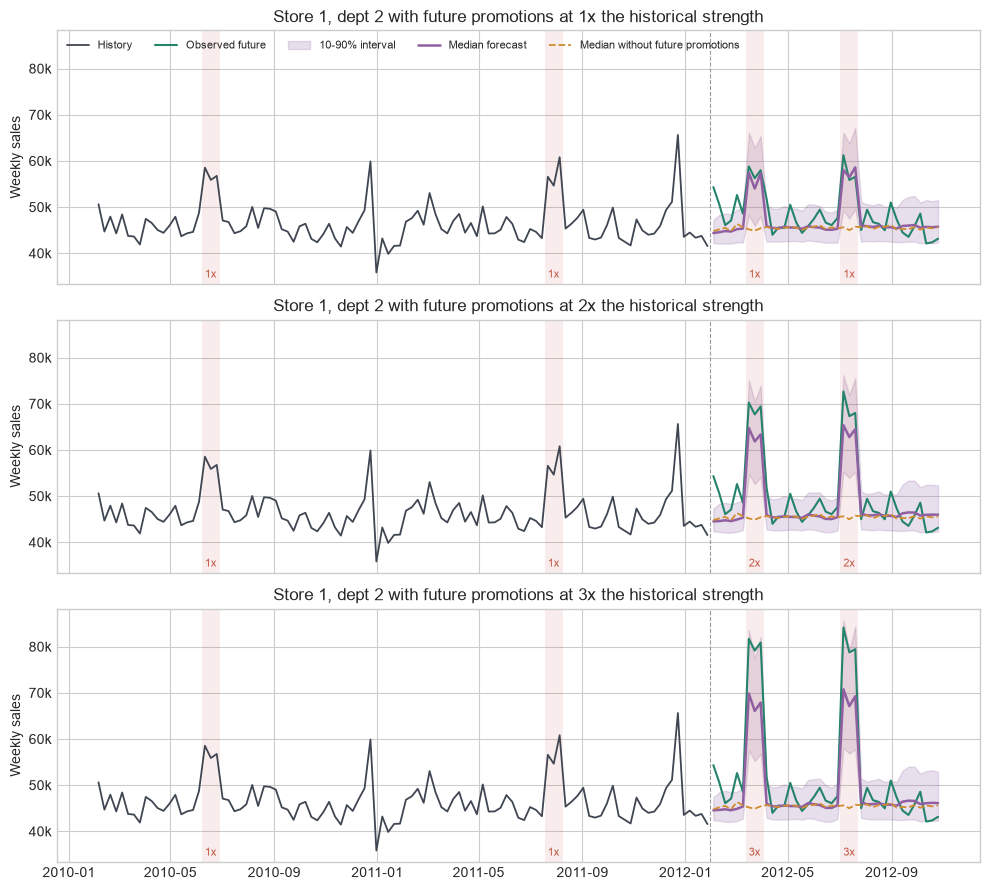

In [10]:
PROMO_ID = "1_2"
PAST_PROMOTIONS = [(18, 21), (76, 79)]  # Week indices; chosen away from holiday weeks.
FUTURE_PROMOTIONS = [(HISTORY + 6, HISTORY + 9), (HISTORY + 22, HISTORY + 25)]
PROMOTION_STRENGTHS = [1.0, 2.0, 3.0]
PROMOTION_COLOR = "#c25645"

promo_base = series(PROMO_ID)
PROMOTION_UPLIFT = 0.25 * promo_base[:HISTORY].mean()

def make_promotion(future_strength, past_strength=1.0):
    promotion = np.zeros(SERIES_LENGTH, dtype=np.float32)
    for start, end in PAST_PROMOTIONS:
        promotion[start:end] = past_strength
    for start, end in FUTURE_PROMOTIONS:
        promotion[start:end] = future_strength
    return promotion

def make_promotion_input(target, promotion):
    return {
        "target": target[:HISTORY],
        "past_covariates": {"promotion": promotion[:HISTORY]},
        "future_covariates": {"promotion": promotion[HISTORY:]},
    }

def shade_promotions(ax, promotion):
    for start, end in PAST_PROMOTIONS + FUTURE_PROMOTIONS:
        left, right = dates[start] - HALF_WEEK, dates[end - 1] + HALF_WEEK
        ax.axvspan(left, right, color=PROMOTION_COLOR, alpha=0.10, lw=0)
        ax.annotate(f"{promotion[start]:g}x", (left + (right - left) / 2, 0.0), xycoords=("data", "axes fraction"),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=PROMOTION_COLOR)

scenario_strengths = [0.0] + PROMOTION_STRENGTHS
scenario_promotions = [make_promotion(future_strength=strength) for strength in scenario_strengths]
scenario_targets = [promo_base + PROMOTION_UPLIFT * promotion for promotion in scenario_promotions]
scenario_quantiles = predict([make_promotion_input(target, promotion) for target, promotion in zip(scenario_targets, scenario_promotions)])
baseline_median = scenario_quantiles[0][:, 1]  # 0x scenario: no future promotions.

fig, axes = plt.subplots(len(PROMOTION_STRENGTHS), 1, figsize=(10, 3.0 * len(PROMOTION_STRENGTHS)), sharex=True, sharey=True)
for ax, strength, target, promotion, quantiles in zip(axes, scenario_strengths[1:], scenario_targets[1:], scenario_promotions[1:], scenario_quantiles[1:]):
    plot_forecast(ax, target[:HISTORY], target[HISTORY:], quantiles,
                  f"{describe(PROMO_ID)} with future promotions at {strength:g}x the historical strength",
                  reference=baseline_median, reference_label="Median without future promotions")
    shade_promotions(ax, promotion)
    for start, end in FUTURE_PROMOTIONS:
        window = slice(start - HISTORY, end - HISTORY)
        predicted_uplift = (quantiles[window, 1] - baseline_median[window]).mean()
        print(f"{strength:g}x promotion from {dates[start].date()}: true uplift {PROMOTION_UPLIFT * strength / 1000:5.1f}k, "
              f"predicted uplift {predicted_uplift / 1000:5.1f}k")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Forecasting with examples

The full ICL format supplies completed support examples before the query. Each example has a target history and its observed future, and the model uses them as demonstrations of how series like the query behave.

Examples should come from series that behave like the query. This section builds examples from the past of the query and of 4 similar series, and compares two ways of choosing the similar series:

- **4a and 4b: clustering.** Cluster all series by the shape of their whole history, then take the query's nearest neighbours in its cluster.
- **4c and 4d: matching the season of interest.** Take the series whose shape over last year's version of the forecast window is closest to the query's.

Section 4e compares both on many series.

### 4a. Clustering Walmart series

Each series' 104-week history is z-normalised (so clusters reflect shape, not sales volume) and grouped with k-means into 8 clusters. Only the history is used, so nothing from the forecast window leaks into the choice of examples. The plot shows each cluster's mean normalised profile, and the printout lists the most common departments per cluster: similar departments in different stores tend to land together.

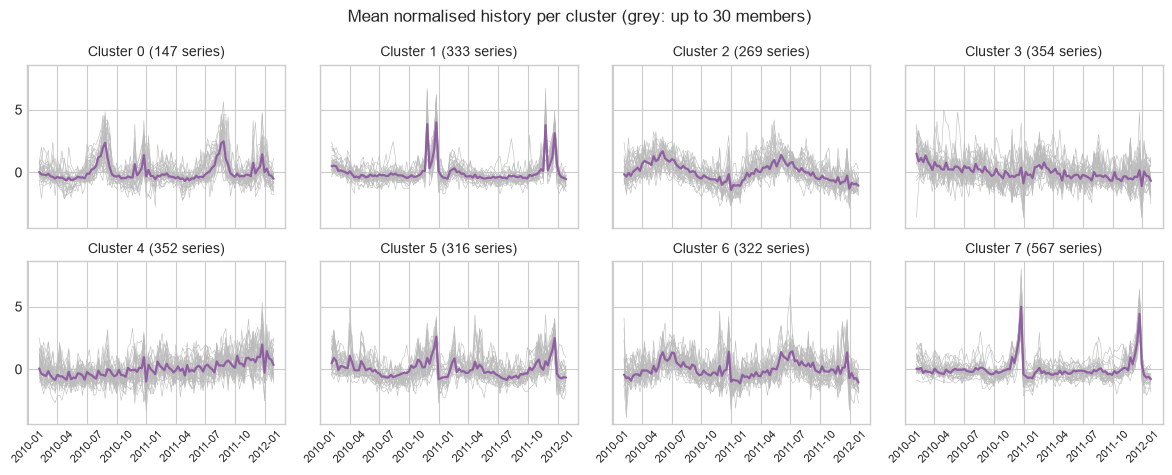

Cluster 0: most common departments 3 (45), 74 (26), 31 (25), 24 (12)
Cluster 1: most common departments 14 (38), 55 (37), 72 (37), 5 (37)
Cluster 2: most common departments 16 (43), 12 (33), 30 (28), 56 (26)
Cluster 3: most common departments 83 (35), 79 (35), 13 (25), 49 (23)
Cluster 4: most common departments 92 (32), 90 (31), 38 (27), 87 (27)
Cluster 5: most common departments 1 (44), 67 (44), 28 (39), 26 (32)
Cluster 6: most common departments 36 (30), 11 (30), 9 (29), 95 (29)
Cluster 7: most common departments 82 (43), 7 (37), 32 (37), 23 (36)


In [11]:
NUM_CLUSTERS = 8

cluster_ids = np.asarray(complete_ids)
cluster_targets = np.stack([series(item_id) for item_id in cluster_ids])
cluster_histories = cluster_targets[:, :HISTORY]
cluster_std = cluster_histories.std(axis=1, keepdims=True)
keep = cluster_std[:, 0] > 0
cluster_ids, cluster_targets, cluster_histories, cluster_std = cluster_ids[keep], cluster_targets[keep], cluster_histories[keep], cluster_std[keep]
normalized_histories = (cluster_histories - cluster_histories.mean(axis=1, keepdims=True)) / cluster_std

kmeans = KMeans(n_clusters=NUM_CLUSTERS, n_init=10, random_state=0).fit(normalized_histories)
cluster_labels = kmeans.labels_

fig, axes = plt.subplots(2, NUM_CLUSTERS // 2, figsize=(12, 4.8), sharex=True, sharey=True)
for cluster, ax in enumerate(axes.ravel()):
    members = cluster_labels == cluster
    ax.plot(history_dates, normalized_histories[members].T[:, :30], color="#bbbbbb", lw=0.4)
    ax.plot(history_dates, kmeans.cluster_centers_[cluster], color=COLORS["forecast"], lw=1.6)
    ax.set_title(f"Cluster {cluster} ({members.sum()} series)", fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("Mean normalised history per cluster (grey: up to 30 members)", fontsize=12)
plt.tight_layout()
plt.show()

departments = pd.Series([item_id.split("_")[1] for item_id in cluster_ids])
for cluster in range(NUM_CLUSTERS):
    top = departments[cluster_labels == cluster].value_counts().head(4)
    print(f"Cluster {cluster}: most common departments " + ", ".join(f"{dept} ({count})" for dept, count in top.items()))

### 4b. Examples from the query and its cluster neighbours

The query is department 3 of store 4. It was picked as an illustration because it has a strong late-summer peak and the effect of examples is easy to see; the next cell shows the typical effect over many series.

To make the role of the examples clear, the query's own context is limited to its **last 52 weeks**, the situation of a series with a short history. The examples are built only from data before the forecast start:

- **Example history**: the 52 weeks from 2010-02-05 to 2011-01-28.
- **Example future**: the following 39 weeks (2011-02-04 to 2011-10-28), the same calendar window as the query's horizon one year earlier.
- **Sources**: the query itself plus its `NUM_NEIGHBOURS = 4` nearest neighbours (Euclidean distance between normalised histories) in its cluster, so 5 examples in total. The model was trained with up to 6 examples.

Query 4_3 is in cluster 0; neighbours: 41_3, 39_3, 32_3, 11_3


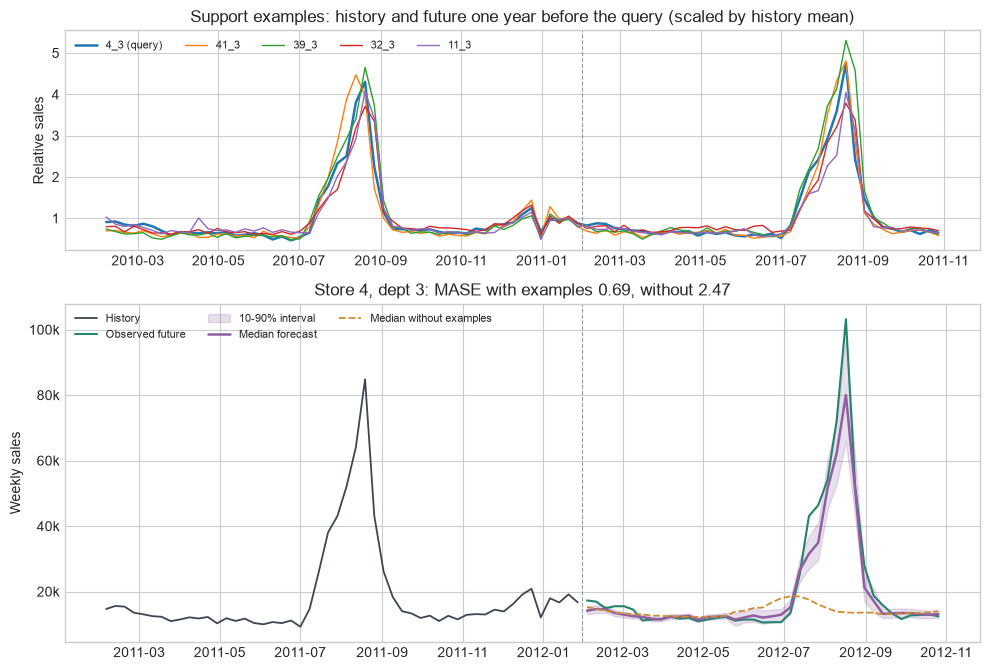

In [12]:
QUERY_ID = "4_3"
QUERY_CONTEXT = 52  # Weeks of the query's own history passed as context.
NUM_NEIGHBOURS = 4
SEASON = 52
EXAMPLE_HISTORY = slice(HISTORY - SEASON - QUERY_CONTEXT, HISTORY - SEASON)
EXAMPLE_FUTURE = slice(HISTORY - SEASON, HISTORY - SEASON + HORIZON)

def nearest_neighbours(index, count):
    candidates = np.flatnonzero((cluster_labels == cluster_labels[index]) & (np.arange(len(cluster_ids)) != index))
    distances = np.linalg.norm(normalized_histories[candidates] - normalized_histories[index], axis=1)
    return candidates[np.argsort(distances)[:count]]

def make_example_input(index, source_indices):
    return {
        "example_target_histories": [cluster_targets[source, EXAMPLE_HISTORY] for source in source_indices],
        "example_target_futures": [cluster_targets[source, EXAMPLE_FUTURE] for source in source_indices],
        "query_target_history": cluster_targets[index, HISTORY - QUERY_CONTEXT:HISTORY],
    }

query_index = int(np.flatnonzero(cluster_ids == QUERY_ID)[0])
neighbour_indices = nearest_neighbours(query_index, NUM_NEIGHBOURS)
example_sources = [query_index, *neighbour_indices]
print(f"Query {QUERY_ID} is in cluster {cluster_labels[query_index]}; neighbours: {', '.join(cluster_ids[neighbour_indices])}")

query_values = cluster_targets[query_index]
example_quantiles = predict([make_example_input(query_index, example_sources)])[0]
short_quantiles = predict(query_values[None, HISTORY - QUERY_CONTEXT:HISTORY])[0]
example_score = mase(query_values[:HISTORY], query_values[HISTORY:], example_quantiles[:, 1])
short_score = mase(query_values[:HISTORY], query_values[HISTORY:], short_quantiles[:, 1])

fig, axes = plt.subplots(2, 1, figsize=(10, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for source in example_sources:
    window = cluster_targets[source, EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop]
    label = f"{cluster_ids[source]} (query)" if source == query_index else cluster_ids[source]
    axes[0].plot(dates[EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop], window / window[:QUERY_CONTEXT].mean(),
                 lw=1.8 if source == query_index else 1.0, label=label)
axes[0].axvline(dates[EXAMPLE_FUTURE.start] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Support examples: history and future one year before the query (scaled by history mean)")
axes[0].set_ylabel("Relative sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)

plot_forecast(axes[1], query_values[HISTORY - QUERY_CONTEXT:HISTORY], query_values[HISTORY:], example_quantiles,
              f"{describe(QUERY_ID)}: MASE with examples {example_score:.2f}, without {short_score:.2f}",
              reference=short_quantiles[:, 1], reference_label="Median without examples")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### 4c. Choosing neighbours by matching the season of interest

Clustering compares whole two-year histories, but the forecast only covers February to October. A more targeted choice compares series only over the **season of interest**: the same calendar window one year earlier (2011-02-04 to 2011-10-28), which is exactly the window used as the example future.

Each series is z-normalised over that window, and the query's neighbours are the `NUM_NEIGHBOURS = 4` series with the smallest Euclidean distance to it, from any cluster. As before, only data from before the forecast start is used.

For the department 3 query of 4b, both methods pick the same four department 3 series, so this section uses a different query: department 34 of store 2 (`SEASON_QUERY_ID = "2_34"`). It was picked as an illustration because its season-matched and cluster neighbours differ (they share one series) and the difference in the forecast is easy to see. Section 4e shows the typical effect. The plot compares the query with both sets of neighbours over the matching window.

Query 2_34 is in cluster 2
Season-matched neighbours: 31_34 (cluster 2), 13_46 (cluster 7), 21_34 (cluster 5), 41_46 (cluster 7)
Cluster neighbours: 6_34 (cluster 2), 31_34 (cluster 2), 6_25 (cluster 2), 15_34 (cluster 2)


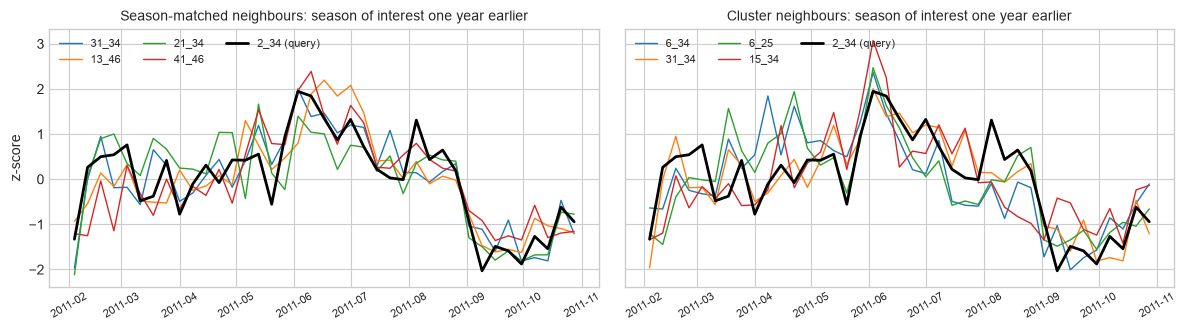

In [13]:
SEASON_QUERY_ID = "2_34"
SEASON_WINDOW = EXAMPLE_FUTURE  # Last year's version of the forecast window.
season_profiles = cluster_targets[:, SEASON_WINDOW]
season_profiles = (season_profiles - season_profiles.mean(axis=1, keepdims=True)) / season_profiles.std(axis=1, keepdims=True).clip(min=1e-6)

def season_neighbours(index, count):
    distances = np.linalg.norm(season_profiles - season_profiles[index], axis=1)
    distances[index] = np.inf
    return np.argsort(distances)[:count]

season_query_index = int(np.flatnonzero(cluster_ids == SEASON_QUERY_ID)[0])
season_indices = season_neighbours(season_query_index, NUM_NEIGHBOURS)
season_cluster_indices = nearest_neighbours(season_query_index, NUM_NEIGHBOURS)
print(f"Query {SEASON_QUERY_ID} is in cluster {cluster_labels[season_query_index]}")
for name, indices in [("Season-matched", season_indices), ("Cluster", season_cluster_indices)]:
    print(f"{name} neighbours: " + ", ".join(f"{cluster_ids[i]} (cluster {cluster_labels[i]})" for i in indices))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (name, indices) in zip(axes, [("Season-matched neighbours", season_indices), ("Cluster neighbours", season_cluster_indices)]):
    for index in indices:
        ax.plot(dates[SEASON_WINDOW], season_profiles[index], lw=1.0, label=cluster_ids[index])
    ax.plot(dates[SEASON_WINDOW], season_profiles[season_query_index], color="black", lw=2.0, label=f"{SEASON_QUERY_ID} (query)")
    ax.set_title(f"{name}: season of interest one year earlier", fontsize=10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
    ax.legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
axes[0].set_ylabel("z-score")
plt.tight_layout()
plt.show()

### 4d. Examples from the query and its season-matched neighbours

The examples are built exactly as in 4b (52-week history, 39-week future one year before the query's horizon), only the 4 neighbours change. The query's context is again limited to its last 52 weeks. The dashed line is the forecast without examples and the dotted line the forecast with cluster-based examples built as in 4b.

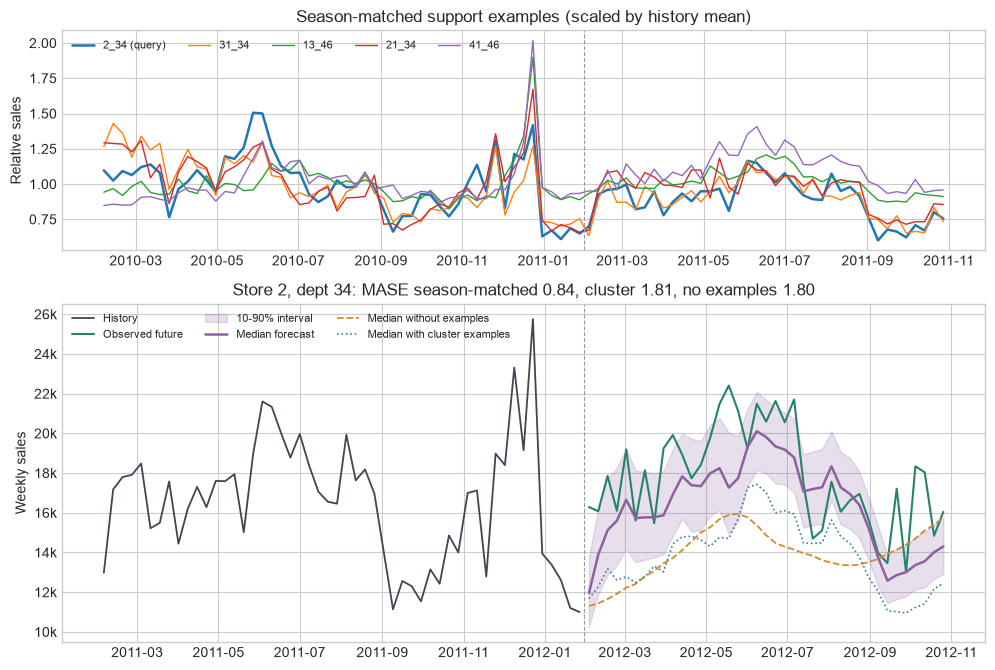

In [14]:
season_values = cluster_targets[season_query_index]
season_sources = [season_query_index, *season_indices]
season_quantiles, season_cluster_quantiles, season_short_quantiles = predict([
    make_example_input(season_query_index, season_sources),
    make_example_input(season_query_index, [season_query_index, *season_cluster_indices]),
    {"query_target_history": season_values[HISTORY - QUERY_CONTEXT:HISTORY]},  # No examples; same dict format so it can share the batch.
])
season_scores = {
    name: mase(season_values[:HISTORY], season_values[HISTORY:], quantiles[:, 1])
    for name, quantiles in [("season", season_quantiles), ("cluster", season_cluster_quantiles), ("none", season_short_quantiles)]
}

fig, axes = plt.subplots(2, 1, figsize=(10, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for source in season_sources:
    window = cluster_targets[source, EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop]
    label = f"{cluster_ids[source]} (query)" if source == season_query_index else cluster_ids[source]
    axes[0].plot(dates[EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop], window / window[:QUERY_CONTEXT].mean(),
                 lw=1.8 if source == season_query_index else 1.0, label=label)
axes[0].axvline(dates[EXAMPLE_FUTURE.start] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Season-matched support examples (scaled by history mean)")
axes[0].set_ylabel("Relative sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)

plot_forecast(axes[1], season_values[HISTORY - QUERY_CONTEXT:HISTORY], season_values[HISTORY:], season_quantiles,
              f"{describe(SEASON_QUERY_ID)}: MASE season-matched {season_scores['season']:.2f}, "
              f"cluster {season_scores['cluster']:.2f}, no examples {season_scores['none']:.2f}",
              reference=season_short_quantiles[:, 1], reference_label="Median without examples")
axes[1].plot(future_dates, season_cluster_quantiles[:, 1], color="#377ca8", lw=1.2, ls=":", label="Median with cluster examples")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### 4e. How much do examples help?

The cell below repeats the comparison for `NUM_EVALUATION_SERIES = 512` random series (fixed seed) and five inputs:

- zero-shot with the full 104-week history (reference),
- zero-shot with the last 52 weeks,
- 52 weeks plus one example from the query's own past,
- 52 weeks plus the query's own example and 4 random series from **other** clusters, to check whether similarity matters,
- 52 weeks plus the query's own example and 4 cluster neighbours (4b),
- 52 weeks plus the query's own example and 4 season-matched neighbours (4d).

In [15]:
NUM_EVALUATION_SERIES = 512  # Set to None to evaluate every series (a few minutes on CPU).

rng = np.random.default_rng(1)
evaluation_indices = (
    np.arange(len(cluster_ids)) if NUM_EVALUATION_SERIES is None
    else rng.choice(len(cluster_ids), size=NUM_EVALUATION_SERIES, replace=False)
)

def random_other_cluster(index, count):
    candidates = np.flatnonzero(cluster_labels != cluster_labels[index])
    return np.random.default_rng(index).choice(candidates, size=count, replace=False)

variants = {
    "zero-shot, 104 weeks": [cluster_targets[i, :HISTORY] for i in evaluation_indices],
    "zero-shot, 52 weeks": [cluster_targets[i, HISTORY - QUERY_CONTEXT:HISTORY] for i in evaluation_indices],
    "52 weeks + own example": [make_example_input(i, [i]) for i in evaluation_indices],
    "52 weeks + own + 4 random other-cluster": [
        make_example_input(i, [i, *random_other_cluster(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
    "52 weeks + own + 4 cluster neighbours": [
        make_example_input(i, [i, *nearest_neighbours(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
    "52 weeks + own + 4 season-matched neighbours": [
        make_example_input(i, [i, *season_neighbours(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
}

results = {}
for name, inputs in variants.items():
    quantiles = predict(inputs)
    results[name] = [
        mase(cluster_targets[i, :HISTORY], cluster_targets[i, HISTORY:], q[:, 1])
        for i, q in zip(evaluation_indices, quantiles)
    ]
results = pd.DataFrame(results)
results.agg(["mean", "median"]).T.round(3)

,mean,median
"zero-shot, 104 weeks",0.784,0.709
"zero-shot, 52 weeks",1.026,0.874
52 weeks + own example,1.019,0.850
52 weeks + own + 4 random other-cluster,0.958,0.822
52 weeks + own + 4 cluster neighbours,0.992,0.805
52 weeks + own + 4 season-matched neighbours,0.946,0.784


What the comparison shows on this dataset. Running it on all 2,660 series gives the same picture, with mean (median) MASE of 0.794 (0.717), 1.031 (0.901), 1.013 (0.873), 0.954 (0.846), 0.968 (0.840), and 0.945 (0.834) for the six rows:

- **Examples help a short-history query.** Adding the query's own example and four other series lowers the error compared with 52-week zero-shot forecasting. One example from the query's own past adds little on its own.
- **How the neighbours are chosen matters only a little.** Cluster neighbours (k-means on the whole history) do no better than random series from other clusters. Season-matched neighbours are the best of the three, but the margin is small. Most of the benefit seems to come from seeing complete history-to-future demonstrations of the same season.
- **A long history is still best.** Zero-shot forecasting with the full 104 weeks beats every 52-week variant, because the query's own two-year history already contains the seasonal information that the examples supply. Examples are most useful when that history is not available, for example for a new store or department.

## Checkpoint scope

This notebook uses the publicly available forecasting checkpoint. iAmTime also supports imputation, anomaly detection, and classification, but checkpoints for those tasks are not currently published.